# Fundamentals of Data Science: Case Study Notebook
**Case Study 1:** Online Retail Baskets  |  **Case Study 4:** Student Dropout and Academic Success

| | |
|---|---|
| **Name** | Anshitha |
| **Roll No.** | 160124733145 |
| **Faculty** | S. Durga Devi |
| **Institution** | Chaitanya Bharathi Institute of Technology |

This notebook is the executable companion to the case study report. Every table and figure in the report comes from the code below. Run the cells from top to bottom (*Kernel > Restart & Run All*).

**Files needed in the same folder as the notebook:** `Online_retail_new.csv` and `Studentdata.csv`.

In [1]:
# ---- Setup -------------------------------------------------------------
import itertools, warnings, os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

# File locations (edit if your files live elsewhere)
RETAIL_CSV  = "Online_retail_new.csv"
STUDENT_CSV = "Studentdata.csv"
FIG_DIR     = "figures"            # every figure is also saved here
os.makedirs(FIG_DIR, exist_ok=True)

# Reproducibility: all random choices use these seeds
CLUSTER_SEED, SAMPLE_SIZE = 7, 1500    # Case Study 1
MODEL_SEED = 2026                      # Case Study 4

# Colour palette used in every chart
NAVY, TEAL, AMBER, CORAL, GREY = "#1F3A5F", "#2A9D8F", "#E9A23B", "#D1495B", "#8A94A0"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E3E6EA", "axes.axisbelow": True,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def show(name):
    """Save the current figure to FIG_DIR and display it."""
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.show()

# Case Study 1: Online Retail Baskets

## 1.1 Load and inspect the data
The CSV has **no header row**: every line is one transaction and its fields hold the products bought. If the file were read with the default header setting, the first basket would be silently lost, so we use `header=None`. We read everything as text so that blank cells are not mistaken for numbers.

In [2]:
raw = pd.read_csv(RETAIL_CSV, header=None, dtype=str, keep_default_na=False)
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,,,,,,,,,,,,,,,,,
2,chutney,,,,,,,,,,,,,,,,,,,
3,turkey,avocado,,,,,,,,,,,,,,,,,,
4,mineral water,milk,energy bar,whole wheat rice,green tea,,,,,,,,,,,,,,,


In [3]:
# Clean: trim spaces, lower-case, and turn blank cells into missing values
raw = raw.apply(lambda col: col.str.strip().str.lower()).replace("", np.nan)

cells = raw.shape[0] * raw.shape[1]
audit = pd.DataFrame({
    "Item": ["Transactions", "Product fields per row", "Non-empty cells", "Empty cells", "Share of empty cells"],
    "Value": [raw.shape[0], raw.shape[1], int(raw.notna().sum().sum()), int(raw.isna().sum().sum()),
              f"{raw.isna().sum().sum() / cells:.1%}"]})
audit

,Item,Value
0,Transactions,7501
1,Product fields per row,20
2,Non-empty cells,29363
3,Empty cells,120657
4,Share of empty cells,80.4%


## 1.2 Build baskets and basket-size statistics

In [4]:
# One basket = list of distinct products in a row (repeats inside a basket are removed)
baskets = [list(dict.fromkeys(row.dropna().tolist())) for _, row in raw.iterrows()]
n = len(baskets)
sizes = pd.Series([len(b) for b in baskets], name="basket_size")

vocab = sorted({item for b in baskets for item in b})
print("Transactions:", n)
print("Distinct products:", len(vocab))
print("Repeated entries removed:", int(raw.notna().sum().sum()) - int(sizes.sum()))
print("Baskets identical to an earlier basket:", pd.Series([tuple(sorted(b)) for b in baskets]).duplicated().sum())

Transactions: 7501
Distinct products: 119
Repeated entries removed: 5
Baskets identical to an earlier basket: 2347


In [5]:
size_stats = pd.DataFrame({"Statistic": ["Mean", "Median", "Mode", "Q1", "Q3", "Minimum", "Maximum", "Std. deviation", "Skewness"],
                           "Value": [sizes.mean(), sizes.median(), sizes.mode()[0], sizes.quantile(.25), sizes.quantile(.75),
                                     sizes.min(), sizes.max(), sizes.std(), stats.skew(sizes)]}).round(2)
display(size_stats)
print(f"Baskets with 3 items or fewer: {(sizes <= 3).mean():.1%}")
print(f"Single-item baskets: {(sizes == 1).sum()} ({(sizes == 1).mean():.1%})")
print(f"Baskets with more than 10 items: {(sizes > 10).sum()}")

,Statistic,Value
0,Mean,3.91
1,Median,3.00
2,Mode,1.00
3,Q1,2.00
4,Q3,5.00
5,Minimum,1.00
6,Maximum,20.00
7,Std. deviation,2.90
8,Skewness,1.19


Baskets with 3 items or fewer: 55.4%
Single-item baskets: 1754 (23.4%)
Baskets with more than 10 items: 256


## 1.3 Product frequency and concentration

In [6]:
freq = pd.Series([item for b in baskets for item in b]).value_counts()
top = pd.DataFrame({"Baskets": freq.head(10), "Share of baskets": (freq.head(10) / n).map("{:.1%}".format)})
display(top)

cum = freq.cumsum() / freq.sum()
print(f"Top 5 products: {freq.head(5).sum():,} of {freq.sum():,} appearances = {freq.head(5).sum() / freq.sum():.1%}")
print("Products needed to cover 50% of appearances:", int((cum < 0.5).sum() + 1))
print("Products needed to cover 80% of appearances:", int((cum < 0.8).sum() + 1))

,Baskets,Share of baskets
mineral water,1788,23.8%
eggs,1348,18.0%
spaghetti,1306,17.4%
french fries,1282,17.1%
chocolate,1229,16.4%
green tea,991,13.2%
milk,972,13.0%
ground beef,737,9.8%
frozen vegetables,715,9.5%
pancakes,713,9.5%


Top 5 products: 6,953 of 29,358 appearances = 23.7%
Products needed to cover 50% of appearances: 17
Products needed to cover 80% of appearances: 45


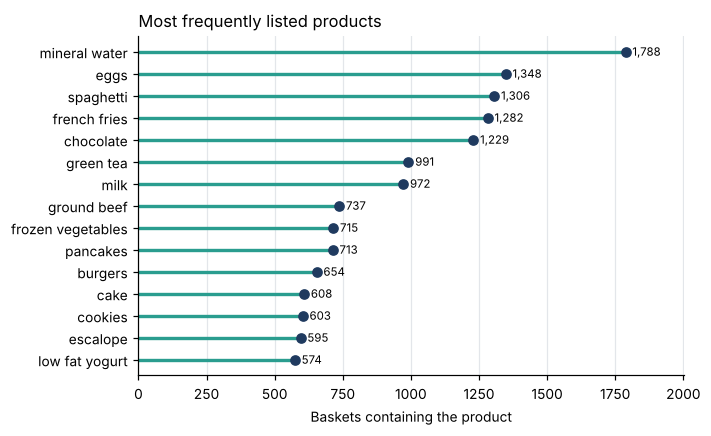

In [7]:
# Figure 1: fifteen most frequent products
t = freq.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.hlines(range(len(t)), 0, t.values, color=TEAL, lw=2.2)
ax.plot(t.values, range(len(t)), "o", color=NAVY, ms=6)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
for i, v in enumerate(t.values):
    ax.text(v + 25, i, f"{v:,}", va="center", fontsize=7.5)
ax.set_xlabel("Baskets containing the product"); ax.set_xlim(0, t.max() * 1.12); ax.grid(axis="y", visible=False)
ax.set_title("Most frequently listed products", loc="left")
show("f1_freq.png")

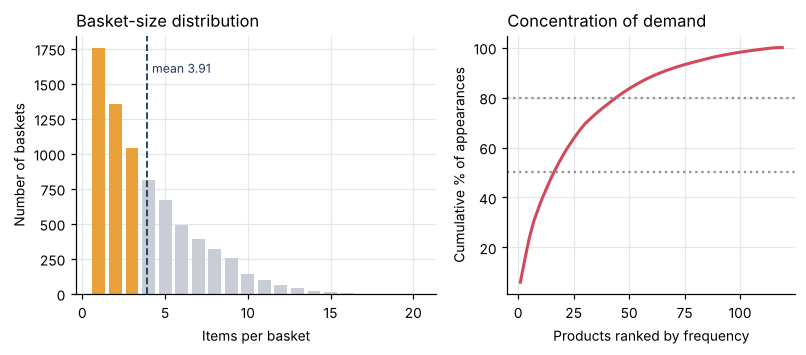

In [8]:
# Figure 2: basket-size distribution and concentration of demand
sc = sizes.value_counts().sort_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.3), gridspec_kw={"width_ratios": [1.25, 1]})
a1.bar(sc.index, sc.values, color=[AMBER if s <= 3 else "#C9CED6" for s in sc.index], width=0.78)
a1.axvline(sizes.mean(), color=NAVY, ls="--", lw=1.2)
a1.text(sizes.mean() + 0.3, sc.max() * 0.9, f"mean {sizes.mean():.2f}", color=NAVY, fontsize=8)
a1.set_xlabel("Items per basket"); a1.set_ylabel("Number of baskets"); a1.set_title("Basket-size distribution", loc="left")
a2.plot(np.arange(1, len(cum) + 1), cum.values * 100, color=CORAL, lw=2)
a2.axhline(50, color=GREY, ls=":"); a2.axhline(80, color=GREY, ls=":")
a2.set_xlabel("Products ranked by frequency"); a2.set_ylabel("Cumulative % of appearances"); a2.set_title("Concentration of demand", loc="left")
plt.tight_layout(); show("f2_size.png")

## 1.4 Product pairs: support, confidence and lift
**Support** is the share of baskets with both products. **Lift** is the observed co-occurrence divided by what independence would give; values above 1 mean a positive association.

In [9]:
pair_counts = Counter()
for b in baskets:
    for pair in itertools.combinations(sorted(b), 2):
        pair_counts[pair] += 1

rows = []
for (a, b), c in pair_counts.items():
    support = c / n
    if support >= 0.008:                      # at least 0.8% of baskets
        rows.append((a, b, c, support, c / freq[a], c / freq[b], support / ((freq[a] / n) * (freq[b] / n))))
pairs = pd.DataFrame(rows, columns=["item_a", "item_b", "baskets", "support", "conf_a_to_b", "conf_b_to_a", "lift"])
print("Pairs with support >= 0.8%:", len(pairs))
print("\nMost frequent pairs")
display(pairs.sort_values("baskets", ascending=False).head(6).round(3))
print("Highest-lift pairs")
display(pairs.sort_values("lift", ascending=False).head(6).round(3))

Pairs with support >= 0.8%: 224

Most frequent pairs


,item_a,item_b,baskets,support,conf_a_to_b,conf_b_to_a,lift
42,mineral water,spaghetti,448,0.060,0.251,0.343,1.439
74,chocolate,mineral water,395,0.053,0.321,0.221,1.348
28,eggs,mineral water,382,0.051,0.283,0.214,1.189
18,milk,mineral water,360,0.048,0.370,0.201,1.554
68,ground beef,mineral water,307,0.041,0.417,0.172,1.748
70,ground beef,spaghetti,294,0.039,0.399,0.225,2.291


Highest-lift pairs


,item_a,item_b,baskets,support,conf_a_to_b,conf_b_to_a,lift
119,ground beef,herb & pepper,120,0.016,0.163,0.323,3.292
114,olive oil,soup,67,0.009,0.136,0.177,2.684
223,milk,whole wheat pasta,74,0.010,0.076,0.335,2.584
104,frozen vegetables,tomatoes,121,0.016,0.169,0.236,2.474
170,frozen vegetables,shrimp,125,0.017,0.175,0.233,2.447
59,milk,soup,114,0.015,0.117,0.301,2.321


## 1.5 Feature engineering and PCA
Each basket becomes a vector of 0/1 values, one per product (multi-hot encoding). PCA is first fitted on all baskets to see how variance is spread, then on a sample for plotting.

In [10]:
index = {item: i for i, item in enumerate(vocab)}
X = np.zeros((n, len(vocab)), dtype=np.uint8)
for r, b in enumerate(baskets):
    for item in b:
        X[r, index[item]] = 1
print("Matrix shape:", X.shape, "| share of entries equal to 1:", f"{X.mean():.2%}")

pca_full = PCA(random_state=0).fit(X.astype(float))
ev = pca_full.explained_variance_ratio_
cv = np.cumsum(ev)
print(f"PC1 = {ev[0]:.2%}, PC2 = {ev[1]:.2%}, first two together = {ev[:2].sum():.2%}")
for target in (0.5, 0.8, 0.9):
    print(f"Components needed for {target:.0%} of variance: {int((cv < target).sum() + 1)}")

Matrix shape: (7501, 119) | share of entries equal to 1: 3.29%
PC1 = 6.72%, PC2 = 4.47%, first two together = 11.18%
Components needed for 50% of variance: 18
Components needed for 80% of variance: 46
Components needed for 90% of variance: 66


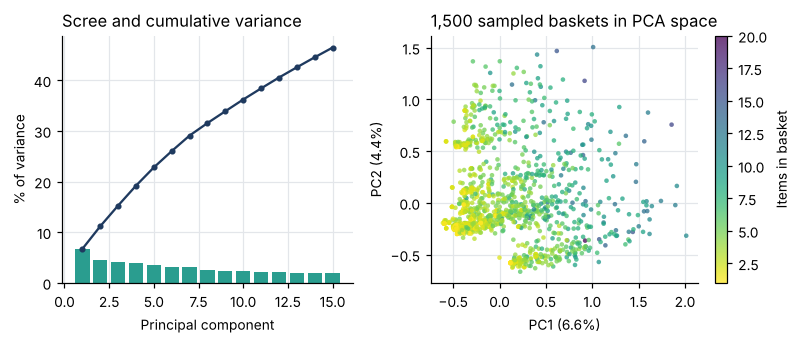

In [11]:
# Sample used for clustering and for all 2-D plots
rng = np.random.RandomState(CLUSTER_SEED)
sample_idx = rng.choice(n, SAMPLE_SIZE, replace=False)
Xs = X[sample_idx].astype(float)
sample_sizes = sizes.values[sample_idx]

pca2 = PCA(n_components=2, random_state=0).fit(Xs)
Z = pca2.transform(Xs)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.2), gridspec_kw={"width_ratios": [1, 1.15]})
a1.bar(range(1, 16), ev[:15] * 100, color=TEAL); a1.plot(range(1, 16), cv[:15] * 100, color=NAVY, marker="o", ms=3)
a1.set_xlabel("Principal component"); a1.set_ylabel("% of variance"); a1.set_title("Scree and cumulative variance", loc="left")
sca = a2.scatter(Z[:, 0], Z[:, 1], c=sample_sizes, cmap="viridis_r", s=9, alpha=.75, linewidths=0)
fig.colorbar(sca, ax=a2).set_label("Items in basket")
a2.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})"); a2.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
a2.set_title(f"{SAMPLE_SIZE:,} sampled baskets in PCA space", loc="left")
plt.tight_layout(); show("f3_pca.png")

## 1.6 Clustering and evaluation
Four algorithms are compared on the same sample. The **silhouette coefficient** (higher is better, range -1 to 1) and the **Davies-Bouldin index** (lower is better) are the internal validity measures. DBSCAN marks isolated baskets as noise (label -1); its scores are computed on the non-noise baskets only.

In [12]:
K = 4
labels = {}
labels["K-means"]      = KMeans(K, n_init=10, random_state=CLUSTER_SEED).fit_predict(Xs)
labels["Hierarchical"] = AgglomerativeClustering(K, linkage="ward").fit_predict(Xs)
labels["DBSCAN"]       = DBSCAN(eps=0.5, min_samples=5, metric="jaccard").fit_predict(Xs.astype(bool))
labels["Spectral"]     = SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=10,
                                            random_state=CLUSTER_SEED, assign_labels="kmeans").fit_predict(Xs)

def score(lab, data):
    keep = lab != -1                                   # ignore DBSCAN noise
    if len(set(lab[keep])) < 2:
        return np.nan, np.nan
    return silhouette_score(data[keep], lab[keep]), davies_bouldin_score(data[keep], lab[keep])

rows = []
for name, lab in labels.items():
    s, d = score(lab, Xs)
    keep = lab != -1
    rows.append({"Algorithm": name, "Clusters": len(set(lab[keep])), "Noise baskets": int((~keep).sum()),
                 "Silhouette": round(s, 4), "Davies-Bouldin": round(d, 4),
                 "Cluster sizes": sorted(pd.Series(lab[keep]).value_counts().tolist(), reverse=True)})
results = pd.DataFrame(rows)
results

,Algorithm,Clusters,Noise baskets,Silhouette,Davies-Bouldin,Cluster sizes
0,K-means,4,0,0.0693,3.1925,"[782, 251, 238, 229]"
1,Hierarchical,4,0,0.0174,4.7786,"[832, 330, 193, 145]"
2,DBSCAN,2,549,0.0872,1.9344,"[945, 6]"
3,Spectral,4,0,-0.0246,3.2183,"[1175, 130, 111, 84]"


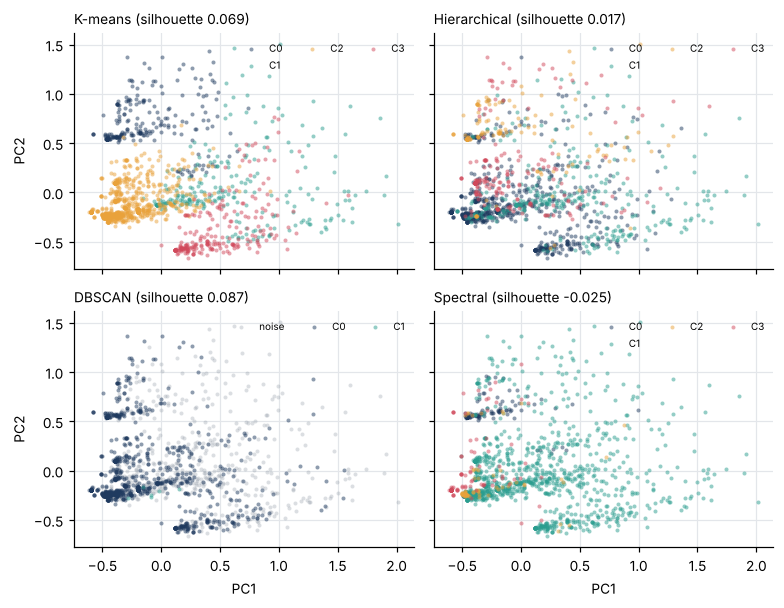

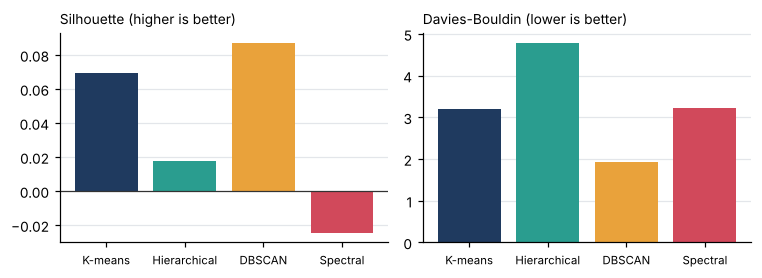

In [13]:
# Figure 4: clusters in PCA space; Figure 5: metric comparison
fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.6), sharex=True, sharey=True)
palette = [NAVY, TEAL, AMBER, CORAL, "#7B5EA7"]
for ax, (name, lab) in zip(axs.ravel(), labels.items()):
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=.5 if c != -1 else .3, linewidths=0,
                   color=GREY if c == -1 else palette[c % 5], label="noise" if c == -1 else f"C{c}")
    sil = results.set_index("Algorithm").loc[name, "Silhouette"]
    ax.set_title(f"{name} (silhouette {sil:.3f})", loc="left", fontsize=9); ax.legend(fontsize=6.5, frameon=False, ncol=3)
for ax in axs[1]: ax.set_xlabel("PC1")
for ax in axs[:, 0]: ax.set_ylabel("PC2")
plt.tight_layout(); show("f4_clusters.png")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7, 2.6))
cols = [NAVY, TEAL, AMBER, CORAL]
a1.bar(results["Algorithm"], results["Silhouette"], color=cols); a1.axhline(0, color="#333", lw=.8); a1.set_title("Silhouette (higher is better)", loc="left", fontsize=9)
a2.bar(results["Algorithm"], results["Davies-Bouldin"], color=cols); a2.set_title("Davies-Bouldin (lower is better)", loc="left", fontsize=9)
for a in (a1, a2): a.tick_params(axis="x", labelsize=7.5); a.grid(axis="x", visible=False)
plt.tight_layout(); show("f5_metrics.png")

### Profile of the K-means clusters
Which products define each cluster?

In [14]:
for c in range(K):
    m = labels["K-means"] == c
    top3 = pd.Series(Xs[m].mean(axis=0), index=vocab).sort_values(ascending=False).head(3)
    desc = ", ".join(f"{i} ({v:.0%})" for i, v in top3.items())
    print(f"Cluster {c}: {m.sum():4d} baskets, mean size {sample_sizes[m].mean():.1f} | most common: {desc}")

Cluster 0:  238 baskets, mean size 4.4 | most common: french fries (100%), eggs (19%), green tea (15%)
Cluster 1:  251 baskets, mean size 6.4 | most common: spaghetti (100%), mineral water (33%), ground beef (26%)
Cluster 2:  782 baskets, mean size 2.7 | most common: eggs (16%), chocolate (12%), green tea (12%)
Cluster 3:  229 baskets, mean size 5.3 | most common: mineral water (100%), chocolate (21%), eggs (20%)


### Sensitivity checks
These show whether the weak clustering result is an accident of one parameter choice or one sample.

In [15]:
# (a) K-means for k = 2..8
km_rows = []
for k in range(2, 9):
    lab = KMeans(k, n_init=10, random_state=CLUSTER_SEED).fit_predict(Xs)
    km_rows.append({"k": k, "Silhouette": round(silhouette_score(Xs, lab), 4), "Davies-Bouldin": round(davies_bouldin_score(Xs, lab), 4)})
display(pd.DataFrame(km_rows))

# (b) DBSCAN over eps and min_samples
db_rows = []
for eps in (0.5, 0.6, 0.7, 0.8, 0.9):
    for ms in (5, 10):
        lab = DBSCAN(eps=eps, min_samples=ms, metric="jaccard").fit_predict(Xs.astype(bool))
        keep = lab != -1
        s, d = score(lab, Xs)
        db_rows.append({"eps": eps, "min_samples": ms, "clusters": len(set(lab[keep])), "noise": int((~keep).sum()),
                        "silhouette": None if np.isnan(s) else round(s, 4)})
display(pd.DataFrame(db_rows))

,k,Silhouette,Davies-Bouldin
0,2,0.1237,3.5442
1,3,0.0996,3.3114
2,4,0.0693,3.1925
3,5,0.0070,3.0624
4,6,0.0174,3.0089
5,7,0.0454,3.0934
6,8,0.0332,2.9862


,eps,min_samples,clusters,noise,silhouette
0,0.5,5,2,549,0.0872
1,0.5,10,1,661,NaN
2,0.6,5,2,275,-0.0437
3,0.6,10,1,383,NaN
4,0.7,5,1,27,NaN
5,0.7,10,1,45,NaN
6,0.8,5,1,1,NaN
7,0.8,10,1,1,NaN
8,0.9,5,1,0,NaN
9,0.9,10,1,0,NaN


In [16]:
# (c) Stability: repeat K-means and Ward on five other random samples
stab = []
for seed in range(1, 6):
    idx = np.random.RandomState(seed).choice(n, SAMPLE_SIZE, replace=False)
    Xt = X[idx].astype(float)
    km = KMeans(K, n_init=10, random_state=seed).fit_predict(Xt)
    hc = AgglomerativeClustering(K, linkage="ward").fit_predict(Xt)
    stab.append((silhouette_score(Xt, km), silhouette_score(Xt, hc)))
stab = np.array(stab)
print(f"K-means silhouette over 5 samples: {stab[:, 0].mean():.3f} +/- {stab[:, 0].std():.3f}")
print(f"Ward    silhouette over 5 samples: {stab[:, 1].mean():.3f} +/- {stab[:, 1].std():.3f}")

K-means silhouette over 5 samples: 0.080 +/- 0.012
Ward    silhouette over 5 samples: 0.022 +/- 0.021


### Case Study 1: findings
* Demand is concentrated: a small group of staples accounts for half of all product appearances, and baskets are short and right-skewed.
* PCA keeps only about 11% of the variance in two dimensions, so the 2-D plots are visual aids only.
* No clustering method gives well-separated groups (all silhouettes below 0.1). DBSCAN's apparently better scores come from discarding about a third of the baskets as noise.
* Co-occurrence measured by lift is more useful for business ideas than the cluster labels.

# Case Study 4: Student Dropout and Academic Success

## 4.1 Part A: data understanding
The file is semicolon-separated and starts with a byte-order mark, so we read it with `sep=";"` and `encoding="utf-8-sig"`. One column name has a trailing tab, which we strip.

In [17]:
df = pd.read_csv(STUDENT_CSV, sep=";", encoding="utf-8-sig")
df.columns = [c.strip() for c in df.columns]
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [18]:
print("Data types:")
print(df.dtypes.value_counts().to_string())
print("\nMissing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nTarget classes:")
print(df["Target"].value_counts().to_string())

Data types:
int64      29
float64     7
str         1

Missing values: 0
Exact duplicate rows: 0

Target classes:
Target
Graduate    2209
Dropout     1421
Enrolled     794


In [19]:
# Classify the predictors by what their values mean, not by their storage type
target = "Target"
binary_cols = [c for c in df.columns if c != target and set(df[c].unique()) <= {0, 1}]
code_cols = ["Marital status", "Application mode", "Course", "Daytime/evening attendance", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
numeric_cols = [c for c in df.columns if c not in binary_cols + code_cols + [target]]

print("Binary indicators :", binary_cols)
print("\nCategorical codes :", code_cols)
print("\nNumerical          :", numeric_cols)

Binary indicators : ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

Categorical codes : ['Marital status', 'Application mode', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

Numerical          : ['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd se

In [20]:
# Unusual values worth checking
g1 = "Curricular units 1st sem (grade)"
print("Students with first-semester grade = 0           :", int((df[g1] == 0).sum()))
print("Students with 0 first-semester units enrolled     :", int((df["Curricular units 1st sem (enrolled)"] == 0).sum()))
print("Enrolled in units but with 0 evaluations          :",
      int(((df["Curricular units 1st sem (evaluations)"] == 0) & (df["Curricular units 1st sem (enrolled)"] > 0)).sum()))
print("Age at enrolment range                            :", df["Age at enrollment"].min(), "to", df["Age at enrollment"].max())

Students with first-semester grade = 0           : 718
Students with 0 first-semester units enrolled     : 180
Enrolled in units but with 0 evaluations          : 169
Age at enrolment range                            : 17 to 70


## 4.2 Part B: exploratory analysis

,Students,Share
Target,,
Dropout,1421,32.1%
Enrolled,794,17.9%
Graduate,2209,49.9%


Accuracy of always predicting 'Graduate': 49.9%


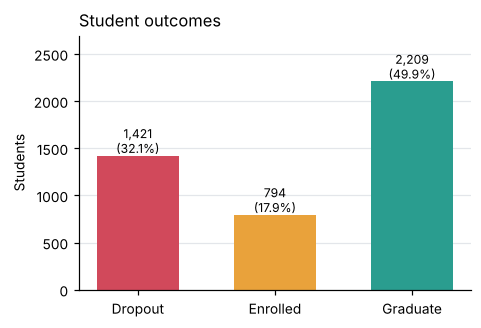

In [21]:
order = ["Dropout", "Enrolled", "Graduate"]
counts = df[target].value_counts().reindex(order)
dist = pd.DataFrame({"Students": counts, "Share": (counts / len(df)).map("{:.1%}".format)})
display(dist)
print("Accuracy of always predicting 'Graduate':", f"{(df[target] == 'Graduate').mean():.1%}")

fig, ax = plt.subplots(figsize=(4.6, 3))
bars = ax.bar(order, counts.values, color=[CORAL, AMBER, TEAL], width=.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 30, f"{v:,}\n({v / len(df):.1%})", ha="center", fontsize=8)
ax.set_ylim(0, counts.max() * 1.22); ax.set_ylabel("Students"); ax.grid(axis="x", visible=False)
ax.set_title("Student outcomes", loc="left"); show("f6_target.png")

,mean,std,min,25%,50%,75%,max,skew
Age at enrollment,23.27,7.59,17.0,19.0,20.00,25.0,70.00,2.05
Admission grade,126.98,14.48,95.0,117.9,126.10,134.8,190.00,0.53
Curricular units 1st sem (grade),10.64,4.84,0.0,11.0,12.29,13.4,18.88,-1.57


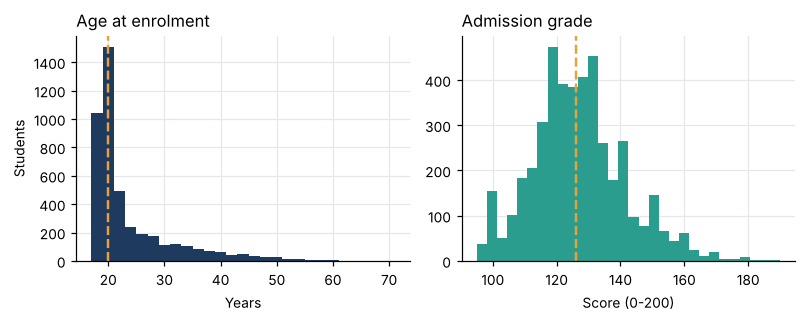

In [22]:
age, adm = "Age at enrollment", "Admission grade"
desc = df[[age, adm, g1]].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["skew"] = [stats.skew(df[c]) for c in (age, adm, g1)]
display(desc.round(2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3))
a1.hist(df[age], bins=range(17, 72, 2), color=NAVY); a1.axvline(df[age].median(), color=AMBER, ls="--", lw=1.6)
a1.set_title("Age at enrolment", loc="left"); a1.set_xlabel("Years"); a1.set_ylabel("Students")
a2.hist(df[adm], bins=30, color=TEAL); a2.axvline(df[adm].median(), color=AMBER, ls="--", lw=1.6)
a2.set_title("Admission grade", loc="left"); a2.set_xlabel("Score (0-200)")
plt.tight_layout(); show("f7_hist.png")

,mean,median,std,Q1,Q3
Target,,,,,
Dropout,124.96,123.6,15.13,115.0,133.00
Enrolled,125.53,124.1,13.79,117.0,133.28
Graduate,128.79,127.4,14.07,119.7,136.40


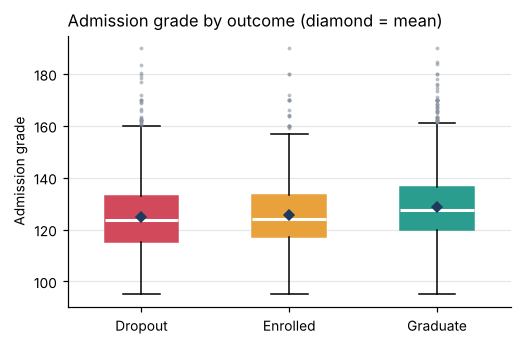

In [23]:
# Admission grade by outcome
display(df.groupby(target)[adm].agg(["mean", "median", "std", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
        .set_axis(["mean", "median", "std", "Q1", "Q3"], axis=1).loc[order].round(2))

fig, ax = plt.subplots(figsize=(5.2, 3.2))
data = [df.loc[df[target] == o, adm] for o in order]
bp = ax.boxplot(data, tick_labels=order, patch_artist=True, widths=.5, medianprops=dict(color="white", lw=2),
                flierprops=dict(marker="o", ms=2.5, mfc=GREY, mec="none", alpha=.6))
for p, c in zip(bp["boxes"], [CORAL, AMBER, TEAL]):
    p.set_facecolor(c); p.set_edgecolor(c)
for i, d in enumerate(data, 1):
    ax.plot(i, d.mean(), "D", color=NAVY, ms=5, zorder=5)
ax.set_ylabel("Admission grade"); ax.set_title("Admission grade by outcome (diamond = mean)", loc="left"); ax.grid(axis="x", visible=False)
show("f8_adm.png")

,count,mean,median,std,grade = 0,share = 0
Target,,,,,,
Dropout,1421,7.26,10.93,6.03,570,40.1%
Enrolled,794,11.13,12.00,3.68,71,8.9%
Graduate,2209,12.64,13.00,2.70,77,3.5%


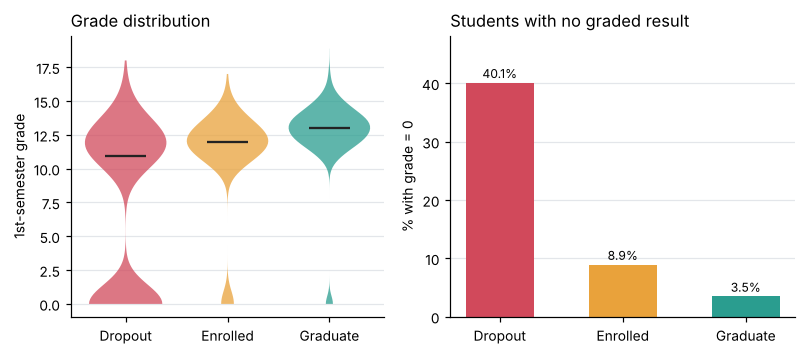

In [24]:
# First-semester grade by outcome
g1_summary = df.groupby(target)[g1].agg(["count", "mean", "median", "std"]).loc[order].round(2)
g1_summary["grade = 0"] = [int(((df[target] == o) & (df[g1] == 0)).sum()) for o in order]
g1_summary["share = 0"] = [f"{((df[target] == o) & (df[g1] == 0)).sum() / (df[target] == o).sum():.1%}" for o in order]
display(g1_summary)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.3), gridspec_kw={"width_ratios": [1, 1.1]})
vp = a1.violinplot([df.loc[df[target] == o, g1] for o in order], showmedians=True, showextrema=False, widths=.8)
for b, c in zip(vp["bodies"], [CORAL, AMBER, TEAL]):
    b.set_facecolor(c); b.set_alpha(.75)
vp["cmedians"].set_color("#222")
a1.set_xticks([1, 2, 3]); a1.set_xticklabels(order); a1.set_ylabel("1st-semester grade"); a1.set_title("Grade distribution", loc="left"); a1.grid(axis="x", visible=False)
zero_share = [((df[target] == o) & (df[g1] == 0)).sum() / (df[target] == o).sum() * 100 for o in order]
bars = a2.bar(order, zero_share, color=[CORAL, AMBER, TEAL], width=.55)
for b, v in zip(bars, zero_share):
    a2.text(b.get_x() + b.get_width() / 2, v + .8, f"{v:.1f}%", ha="center", fontsize=8)
a2.set_ylabel("% with grade = 0"); a2.set_title("Students with no graded result", loc="left"); a2.set_ylim(0, max(zero_share) * 1.2); a2.grid(axis="x", visible=False)
plt.tight_layout(); show("f9_g1.png")

,mean,median,std
Target,,,
Dropout,26.07,23.0,8.70
Enrolled,22.37,20.0,6.30
Graduate,21.78,19.0,6.69


Share aged over 30: {'Dropout': '25.0%', 'Enrolled': '10.6%', 'Graduate': '10.1%'}


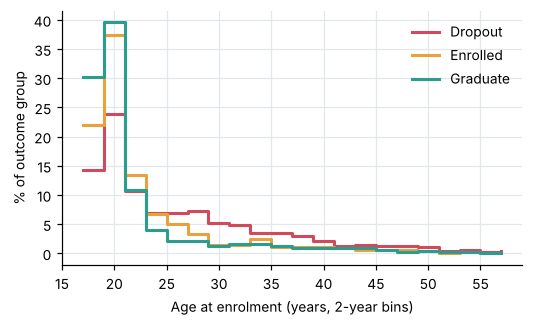

In [25]:
# Age at enrolment by outcome
display(df.groupby(target)[age].agg(["mean", "median", "std"]).loc[order].round(2))
print("Share aged over 30:", {o: f"{((df[target] == o) & (df[age] > 30)).sum() / (df[target] == o).sum():.1%}" for o in order})

fig, ax = plt.subplots(figsize=(5.4, 3))
bins = np.arange(17, 61, 2)
for o, c in zip(order, [CORAL, AMBER, TEAL]):
    h, _ = np.histogram(df.loc[df[target] == o, age], bins=bins)
    ax.step(bins[:-1], h / h.sum() * 100, where="post", color=c, lw=2, label=o)
ax.set_xlabel("Age at enrolment (years, 2-year bins)"); ax.set_ylabel("% of outcome group"); ax.legend(frameon=False)
show("f10_age.png")

## 4.3 Part C: hypothesis test
**Research question:** is the distribution of first-semester grades the same in all three outcome groups?

* H0: the distributions are the same in the three groups.
* H1: at least one group has a different distribution.
* Test: **Kruskal-Wallis H** (three independent groups, no normality assumption needed, grades are skewed with a spike at zero).
* Significance level: alpha = 0.05.

In [26]:
groups = [df.loc[df[target] == o, g1] for o in order]
H, p = stats.kruskal(*groups)
eps2 = H / (len(df) - 1)                                    # epsilon-squared effect size
print(f"Kruskal-Wallis H = {H:.3f}, p-value = {p:.4e}, epsilon-squared = {eps2:.3f}")
print("Decision at alpha = 0.05:", "reject H0" if p < 0.05 else "fail to reject H0")

lev_stat, lev_p = stats.levene(*groups)
print(f"Levene test for equal spread: statistic = {lev_stat:.1f}, p = {lev_p:.2e}  (unequal spread, so read as a difference in distributions)")

# Same test for admission grade and age, to separate statistical from practical significance
for col in (adm, age):
    h, pv = stats.kruskal(*[df.loc[df[target] == o, col] for o in order])
    print(f"{col:20s} H = {h:8.2f}  p = {pv:.2e}  epsilon-squared = {h / (len(df) - 1):.3f}")

Kruskal-Wallis H = 1094.186, p-value = 2.5143e-238, epsilon-squared = 0.247
Decision at alpha = 0.05: reject H0
Levene test for equal spread: statistic = 549.9, p = 5.47e-214  (unequal spread, so read as a difference in distributions)
Admission grade      H =    73.23  p = 1.25e-16  epsilon-squared = 0.017
Age at enrollment    H =   375.11  p = 3.52e-82  epsilon-squared = 0.085


In [27]:
# Post-hoc pairwise tests with Bonferroni correction (3 comparisons)
rows = []
for a, b in itertools.combinations(order, 2):
    x, y = df.loc[df[target] == a, g1], df.loc[df[target] == b, g1]
    u, pv = stats.mannwhitneyu(x, y)
    rows.append({"Pair": f"{a} vs {b}", "Adjusted p": min(1, pv * 3), "Rank-biserial r": 1 - 2 * u / (len(x) * len(y))})
pd.DataFrame(rows).round(4)

,Pair,Adjusted p,Rank-biserial r
0,Dropout vs Enrolled,0.0,0.3469
1,Dropout vs Graduate,0.0,0.6176
2,Enrolled vs Graduate,0.0,0.4017


## 4.4 Part D: classification model
**Leakage control:** the outcome is only known at the end of the course, so the six *2nd sem* columns are removed. The model then relies on information available after the first semester.

All preprocessing (imputation, one-hot encoding, scaling) sits inside one `Pipeline`, so it is fitted on training data only.

In [28]:
second_sem = [c for c in df.columns if "2nd sem" in c]
print("Excluded second-semester columns:", len(second_sem))

X_all = df.drop(columns=[target] + second_sem)
y_all = df[target]
cat_features = [c for c in code_cols if c in X_all.columns]
num_features = [c for c in X_all.columns if c not in cat_features]   # numeric + binary
print("Predictors:", X_all.shape[1], "| categorical codes:", len(cat_features), "| numeric/binary:", len(num_features))

def make_model(class_weight=None):
    pre = ColumnTransformer([
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_features)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000, class_weight=class_weight))])

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=MODEL_SEED)
print("Train / test sizes:", len(X_train), "/", len(X_test))

model = make_model().fit(X_train, y_train)
pred = model.predict(X_test)
print("Model features after encoding:", len(model.named_steps["pre"].get_feature_names_out()))

Excluded second-semester columns: 6
Predictors: 30 | categorical codes: 10 | numeric/binary: 20
Train / test sizes: 3539 / 885


Model features after encoding: 231


,Pred Dropout,Pred Enrolled,Pred Graduate
Actual Dropout,209,27,48
Actual Enrolled,33,55,71
Actual Graduate,27,20,395


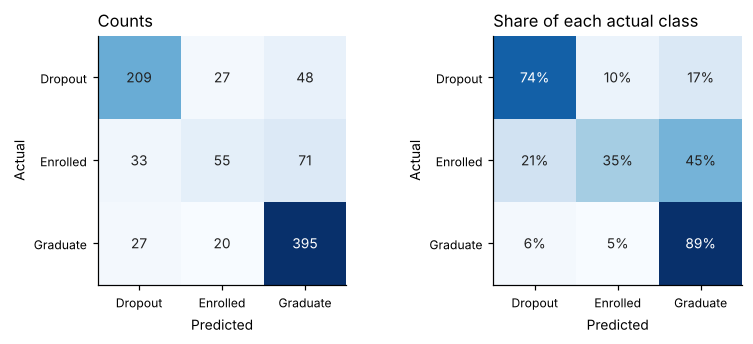

In [29]:
cm = confusion_matrix(y_test, pred, labels=order)
display(pd.DataFrame(cm, index=[f"Actual {o}" for o in order], columns=[f"Pred {o}" for o in order]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.2))
for ax, M, title, fmt in ((a1, cm, "Counts", "{:.0f}"), (a2, cm / cm.sum(axis=1, keepdims=True), "Share of each actual class", "{:.0%}")):
    ax.imshow(M, cmap="Blues"); ax.grid(False)
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(order, fontsize=8); ax.set_yticklabels(order, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title, loc="left")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="white" if M[i, j] > M.max() * .55 else "#222")
plt.tight_layout(); show("f11_cm.png")

              precision    recall  f1-score   support

     Dropout      0.777     0.736     0.756       284
    Enrolled      0.539     0.346     0.421       159
    Graduate      0.768     0.894     0.826       442

    accuracy                          0.745       885
   macro avg      0.695     0.658     0.668       885
weighted avg      0.730     0.745     0.731       885



,Precision,Recall,F1,Support
Dropout,0.777,0.736,0.756,284
Enrolled,0.539,0.346,0.421,159
Graduate,0.768,0.894,0.826,442


Accuracy     : 0.745
Macro F1     : 0.668
Weighted F1  : 0.731
Majority-class baseline accuracy: 0.499


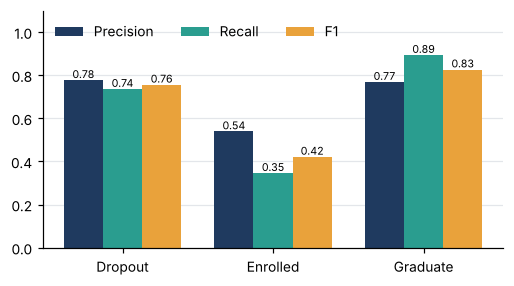

In [30]:
print(classification_report(y_test, pred, labels=order, digits=3))

p_, r_, f_, s_ = precision_recall_fscore_support(y_test, pred, labels=order, zero_division=0)
metrics = pd.DataFrame({"Precision": p_, "Recall": r_, "F1": f_, "Support": s_}, index=order)
display(metrics.round(3))
print(f"Accuracy     : {accuracy_score(y_test, pred):.3f}")
print(f"Macro F1     : {f_.mean():.3f}")
print(f"Weighted F1  : {np.average(f_, weights=s_):.3f}")
print(f"Majority-class baseline accuracy: {(y_test == 'Graduate').mean():.3f}")

fig, ax = plt.subplots(figsize=(5.4, 2.8)); xx = np.arange(3); w = .26
for k, (lab, vals, c) in enumerate((("Precision", p_, NAVY), ("Recall", r_, TEAL), ("F1", f_, AMBER))):
    bars = ax.bar(xx + (k - 1) * w, vals, w, label=lab, color=c)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + .01, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(xx); ax.set_xticklabels(order); ax.set_ylim(0, 1.1); ax.legend(frameon=False, ncol=3, loc="upper left"); ax.grid(axis="x", visible=False)
show("f12_prf.png")

### Robustness checks
1. **5-fold stratified cross-validation:** is the held-out result stable?
2. **Class-balanced weights:** what happens to the weak Enrolled class?
3. **Retrospective model with 2nd-semester data:** how much signal is lost when predictions must be early?

In [31]:
skf = StratifiedKFold(5, shuffle=True, random_state=MODEL_SEED)
cv_acc = cross_val_score(make_model(), X_all, y_all, cv=skf, scoring="accuracy")
cv_f1  = cross_val_score(make_model(), X_all, y_all, cv=skf, scoring="f1_macro")
print(f"5-fold CV accuracy: {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}")
print(f"5-fold CV macro F1: {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}")

# Class-balanced variant
bal_pred = make_model("balanced").fit(X_train, y_train).predict(X_test)
bp, br, bf, _ = precision_recall_fscore_support(y_test, bal_pred, labels=order, zero_division=0)

# Retrospective variant: include 2nd-semester columns (not usable for early warning)
Xr = df.drop(columns=[target])
num_r = [c for c in Xr.columns if c not in cat_features]
pre_r = ColumnTransformer([
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_r)])
retro = Pipeline([("pre", pre_r), ("clf", LogisticRegression(max_iter=3000))])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, y_all, test_size=0.2, stratify=y_all, random_state=MODEL_SEED)
retro_pred = retro.fit(Xr_tr, yr_tr).predict(Xr_te)
rp, rr, rf, _ = precision_recall_fscore_support(yr_te, retro_pred, labels=order, zero_division=0)

summary = pd.DataFrame({
    "Accuracy":         [accuracy_score(y_test, pred), accuracy_score(y_test, bal_pred), accuracy_score(yr_te, retro_pred)],
    "Macro F1":         [f_.mean(), bf.mean(), rf.mean()],
    "Dropout recall":   [r_[0], br[0], rr[0]],
    "Enrolled recall":  [r_[1], br[1], rr[1]],
    "Enrolled precision": [p_[1], bp[1], rp[1]]},
    index=["Baseline (early, first-semester only)", "Class-balanced weights", "Retrospective (adds 2nd semester)"])
summary.round(3)

5-fold CV accuracy: 0.751 +/- 0.020
5-fold CV macro F1: 0.665 +/- 0.026


,Accuracy,Macro F1,Dropout recall,Enrolled recall,Enrolled precision
"Baseline (early, first-semester only)",0.745,0.668,0.736,0.346,0.539
Class-balanced weights,0.714,0.678,0.690,0.604,0.419
Retrospective (adds 2nd semester),0.775,0.708,0.750,0.421,0.588


## 4.5 Part E: interpreting the model

Numeric and binary predictors (inputs standardised, so magnitudes are comparable):


,Dropout,Enrolled,Graduate
Curricular units 1st sem (approved),-1.784,-0.423,2.206
Curricular units 1st sem (enrolled),0.717,0.225,-0.941
Tuition fees up to date,-0.602,0.115,0.487
Curricular units 1st sem (credited),0.511,-0.248,-0.263
Curricular units 1st sem (evaluations),-0.065,0.382,-0.316
Curricular units 1st sem (grade),-0.184,-0.082,0.266
Unemployment rate,0.251,-0.152,-0.099
Debtor,0.150,0.082,-0.233
Scholarship holder,-0.129,-0.100,0.229
Age at enrollment,0.217,-0.072,-0.146


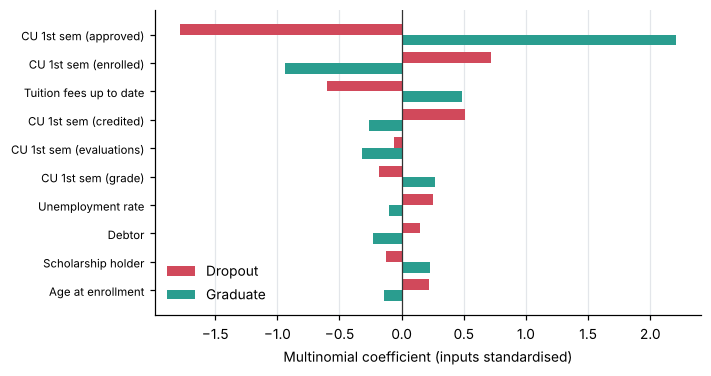

In [32]:
names = [n_.replace("num__", "").replace("cat__", "") for n_ in model.named_steps["pre"].get_feature_names_out()]
coef = pd.DataFrame(model.named_steps["clf"].coef_.T, index=names, columns=model.named_steps["clf"].classes_)

numeric_coef = coef.loc[[c for c in num_features if c in coef.index]]
print("Numeric and binary predictors (inputs standardised, so magnitudes are comparable):")
display(numeric_coef.reindex(numeric_coef.abs().max(axis=1).sort_values(ascending=False).index).round(3).head(12))

sub = numeric_coef[["Dropout", "Graduate"]].copy()
sub["mag"] = sub.abs().max(axis=1)
sub = sub.sort_values("mag", ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.4, 3.6)); yy = np.arange(len(sub)); h = .38
ax.barh(yy + h / 2, sub["Dropout"], h, color=CORAL, label="Dropout"); ax.barh(yy - h / 2, sub["Graduate"], h, color=TEAL, label="Graduate")
ax.set_yticks(yy); ax.set_yticklabels([s.replace("Curricular units", "CU") for s in sub.index], fontsize=7.5)
ax.axvline(0, color="#333", lw=.8); ax.legend(frameon=False); ax.grid(axis="y", visible=False)
ax.set_xlabel("Multinomial coefficient (inputs standardised)"); show("f13_coef.png")

**Reading the coefficients.** The largest effect is the number of first-semester units *approved*: more approved units pushes a student away from Dropout and towards Graduate. Fees up to date, scholarship status, debt, age and the unemployment rate point in the expected directions. Coefficients of one-hot categories with few students (parental occupation or qualification codes) are unstable and are not interpreted. None of these coefficients shows that a characteristic *causes* dropout.

### Case Study 4: findings
* First-semester grade differs strongly across outcomes (Kruskal-Wallis, p far below 0.05, epsilon-squared about 0.25). Admission grade and age differ with much smaller effects.
* About 40% of dropouts have a first-semester grade of 0, against about 3.5% of graduates.
* The early-information logistic regression reaches about 74.5% accuracy and macro F1 of about 0.67. It recognises graduates and dropouts reasonably well but finds only about one in three Enrolled students.
* Class weighting improves Enrolled recall at the cost of precision and accuracy. Model output must support human review, never automatic penalties.

## Reproducibility notes
* Seeds: clustering sample 7 (1,500 baskets); train/test split and cross-validation 2026.
* Libraries: pandas, numpy, scipy, scikit-learn, matplotlib.
* All figures are written to the `figures/` folder.